In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df= pd.read_csv('data.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

In [ ]:
from scipy import stats

In [ ]:
from sklearn import preprocessing

In [ ]:
df=df.to_numpy()

In [ ]:
np.shape(df)

(6819, 96)

In [ ]:
df

array([[1.        , 0.37059426, 0.42438945, ..., 0.56405011, 1.        ,
        0.01646874],
       [1.        , 0.46429094, 0.53821413, ..., 0.57017495, 1.        ,
        0.02079431],
       [1.        , 0.42607127, 0.49901875, ..., 0.56370608, 1.        ,
        0.01647411],
       ...,
       [0.        , 0.47272461, 0.533744  , ..., 0.5651584 , 1.        ,
        0.09764874],
       [0.        , 0.50626432, 0.5599106 , ..., 0.56530151, 1.        ,
        0.04400945],
       [0.        , 0.49305319, 0.57010467, ..., 0.56516694, 1.        ,
        0.23390224]])

In [ ]:
df=np.transpose(df)

In [ ]:
y = np.transpose(df[0])
X = np.transpose(df[1:])

In [ ]:
np.shape(X),np.shape(y)

((6819, 95), (6819,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train, X_train_val, y_train, y_train_val = train_test_split(X_train, y_train, test_size=0.15, random_state=0)

In [ ]:
np.shape(X_train),np.shape(y_train),np.shape(X_test),np.shape(y_test)

((4636, 95), (4636,), (1364, 95), (1364,))

In [ ]:
np.shape(X_train_val),np.shape(y_train_val)

((819, 95), (819,))

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

In [ ]:
model = Sequential([
    Dense(256, activation='sigmoid', input_shape=(X_train.shape[1],)),
    Dense(1, activation='sigmoid')
])

In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
history=model.fit(X_train, y_train, epochs=500, batch_size=150,\
                   validation_data = (X_train_val, y_train_val))

Epoch 1/500
31/31 [==============================] - 2s 24ms/step - loss: 0.3634 - accuracy: 0.8572 - val_loss: 0.1436 - val_accuracy: 0.9731
Epoch 2/500
31/31 [==============================] - 0s 11ms/step - loss: 0.1513 - accuracy: 0.9672 - val_loss: 0.1285 - val_accuracy: 0.9731
Epoch 3/500
31/31 [==============================] - 0s 10ms/step - loss: 0.1487 - accuracy: 0.9672 - val_loss: 0.1274 - val_accuracy: 0.9731
Epoch 4/500
31/31 [==============================] - 0s 9ms/step - loss: 0.1480 - accuracy: 0.9672 - val_loss: 0.1269 - val_accuracy: 0.9731
Epoch 5/500
31/31 [==============================] - 0s 9ms/step - loss: 0.1472 - accuracy: 0.9672 - val_loss: 0.1264 - val_accuracy: 0.9731
Epoch 6/500
31/31 [==============================] - 0s 11ms/step - loss: 0.1463 - accuracy: 0.9672 - val_loss: 0.1255 - val_accuracy: 0.9731
Epoch 7/500
31/31 [==============================] - 0s 10ms/step - loss: 0.1455 - accuracy: 0.9672 - val_loss: 0.1252 - val_accuracy: 0.9731
Epoch 8/

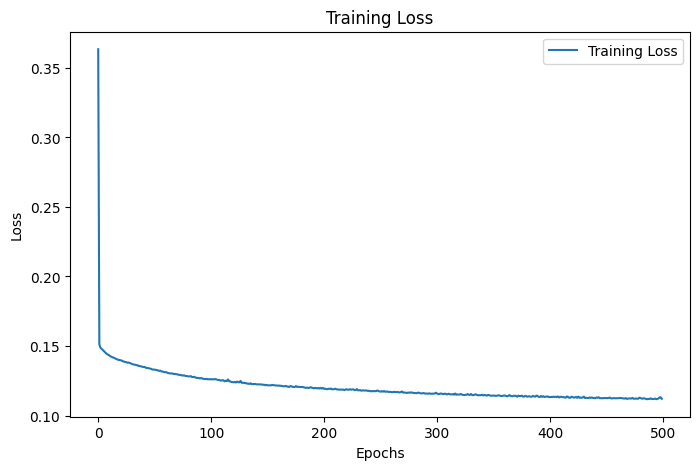

In [ ]:
# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

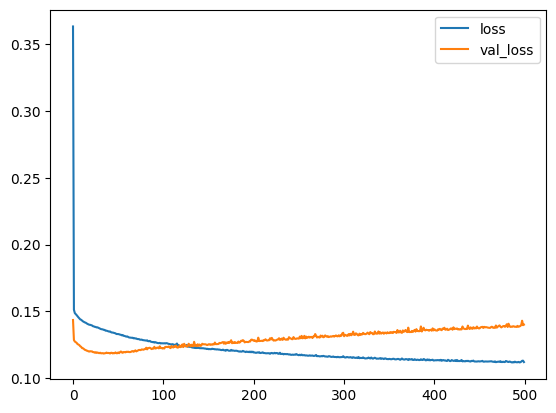

In [ ]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.show()

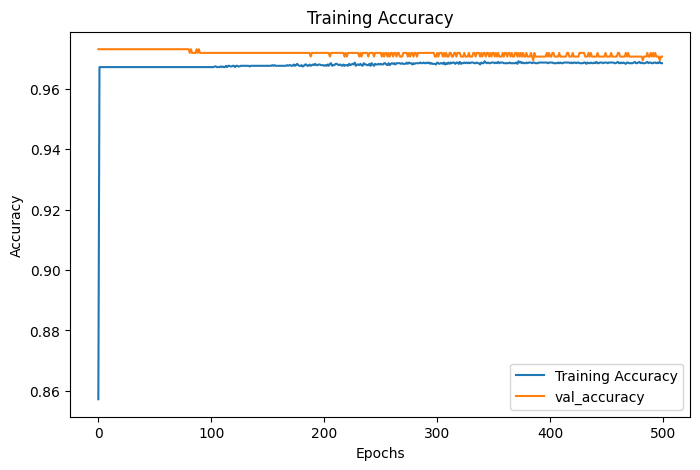

In [ ]:
# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Prediction on test data
predictions = model.predict(X_test)
predicted_classes = np.round(predictions).flatten()

# Assuming binary classification (0 or 1)
accuracy = np.mean(predicted_classes == y_test)
print(f"Test Accuracy: {accuracy*100}%")

43/43 [==============================] - 0s 2ms/step
Test Accuracy: 96.5542521994135%


In [ ]:
# import evaluation tools
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc

In [ ]:
# evaluate result
print("Accuracy:",accuracy_score(y_test, predicted_classes, normalize=True, sample_weight=None))
print("Confusion Matrix:", '\n', confusion_matrix(y_test, predicted_classes))

Accuracy: 0.9655425219941349
Confusion Matrix: 
 [[1317    1]
 [  46    0]]


In [ ]:
print("Non-bankrupted(value=0): ",np.count_nonzero(y_test==0))
print("Bankrupted(value=1): ",np.count_nonzero(y_test))

Non-bankrupted(value=0):  1318
Bankrupted(value=1):  46


In [ ]:
test_confusion_matrix=confusion_matrix(y_test, predicted_classes)

In [ ]:
print("Recall=TP/(TP+FN)= ",test_confusion_matrix[1,1]/(test_confusion_matrix[1,1]+test_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.0


In [ ]:
#prob of bankrupted (value=1)
predictions

array([[0.00633098],
       [0.01607405],
       [0.2694654 ],
       ...,
       [0.00425434],
       [0.01341479],
       [0.02697779]], dtype=float32)

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, predictions)

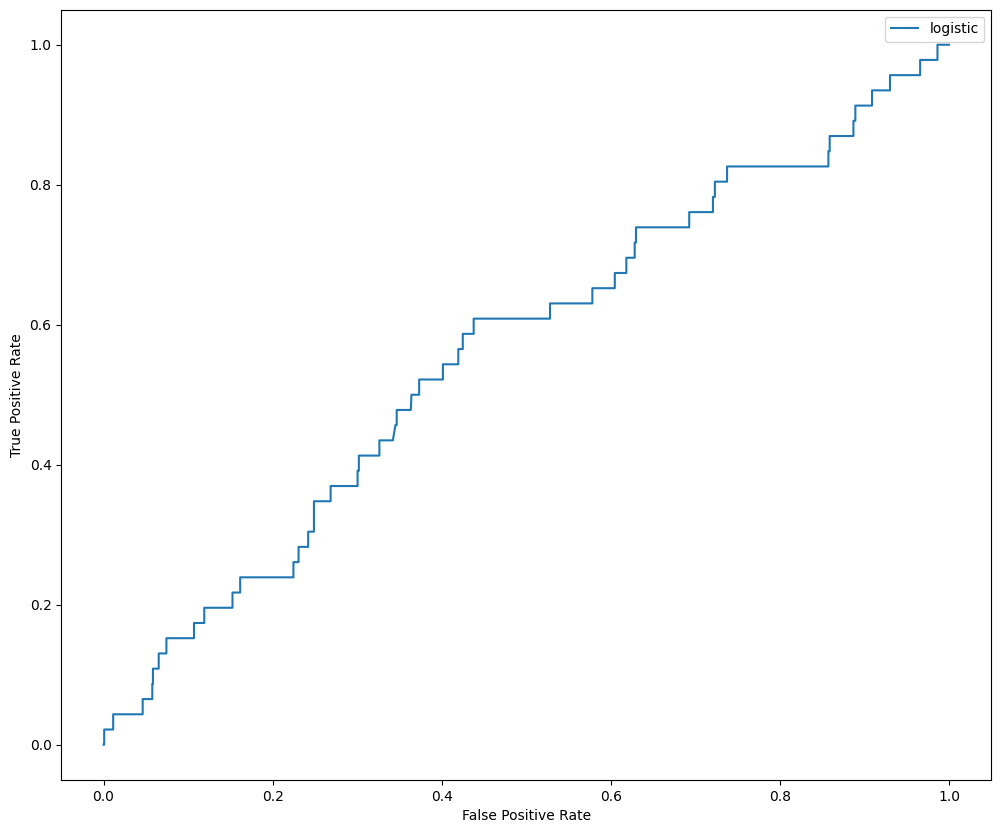

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(fpr, tpr, label="logistic")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
auc = auc(fpr, tpr)

# Print results
pd.DataFrame({"Model":['Artificial Neural Network'], "AUC":[auc]})

,Model,AUC
0,Artificial Neural Network,0.562982


In [ ]:
#Investor perspective: Highly aware if the company would go bankrupt
#Set the prediction threshold to be 0.15, if the probability of
#going bankrupt is larger than 15%, then it would be predictied as True.

In [ ]:
investor_prediction=np.copy(predictions)

In [ ]:
investor_predict_bankeuptcy=[]

In [ ]:
for i in range(np.shape(investor_prediction)[0]):
  if investor_prediction[i]<=0.15:
    investor_predict_bankeuptcy.append(0)
  else:
    investor_predict_bankeuptcy.append(1)

In [ ]:
print(investor_predict_bankeuptcy)

[0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 

In [ ]:
print(f'This is confusion matrix for decision tree in investor perspective: \n{confusion_matrix(y_test, investor_predict_bankeuptcy)}')

This is confusion matrix for decision tree in investor perspective: 
[[1267   51]
 [  44    2]]


In [ ]:
investor_confusion_matrix=np.copy(confusion_matrix(y_test, investor_predict_bankeuptcy))

In [ ]:
print("In investor perspective: Recall=TP/(TP+FN)= ",investor_confusion_matrix[1,1]/(investor_confusion_matrix[1,1]+investor_confusion_matrix[1,0]))

In investor perspective: Recall=TP/(TP+FN)=  0.043478260869565216


In [ ]:
#We set cost as getting FP is 1, while FN is 10
#FP means investors would falsely identify a non-bankrupt company as bankrupt
#FN means investors would falsely identify a bankrupt company as non-bankrupt
#The cost of FN should be much higher than FP.
#Higher the cost, the worse it is.

In [ ]:
print("Cost:",investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10)

Cost: 491


In [ ]:
cost=investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10

In [ ]:
#We set gain of TP is 5, while TN is 0.5
#TP means investors would correctly identify a bankrupt company as bankrupt
#TN means investors would correctly identify a non-bankrupt company as non-bankrupt
#The gain of TP should be higher than TN
#In investors perspective, FP and FN should be more aware
#The value of cost should be larger than the value of gain
#because even it is non-bankrupt, it does not mean investor
#would earn a lot in that company
#Higher the gain, the better it is.

In [ ]:
print("Gain:", investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5)

Gain: 136.7


In [ ]:
#Net cost is used to calculate the cost including the earning when we correctly identify
#Net cost=cost-gain
#Higher the net cost, the worse it is.

In [ ]:
gain=investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5

In [ ]:
print("Net cost:", cost-gain)

Net cost: 354.3


In [ ]:
print("Recall=TP/(TP+FN)= ",investor_confusion_matrix[1,1]/(investor_confusion_matrix[1,1]+investor_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.043478260869565216
